# Importing torch

In [1]:
import torch
from torch import nn

torch.__version__

'2.13.0'

# First steps
1. Tensors
2. FeedForward layer
3. Activation functions
4. Inference
5. Simple NN
6. Classifying with torch

## Tensors

In [2]:
data = torch.tensor([[1,2,3,3],[4,5,6,6],[7,8,9,9]])
print(data.size())
print(data)
print(data.dtype)

torch.Size([3, 4])
tensor([[1, 2, 3, 3],
        [4, 5, 6, 6],
        [7, 8, 9, 9]])
torch.int64


In [3]:
random_input = torch.randn(2,3,4) # First dimension always relates to number of samples. Here each sample is a matrix of shape 3x4
print(random_input.size())
print(random_input)

torch.Size([2, 3, 4])
tensor([[[-0.8000, -0.2152,  0.2496, -0.7505],
         [ 1.8946, -1.1818, -1.6010, -0.3536],
         [-0.7362,  1.0342, -0.0335, -0.3801]],

        [[ 1.8578,  2.5536,  0.3528,  1.5458],
         [-1.1653, -0.4481, -0.3277, -1.3330],
         [-1.1789, -0.1317, -0.5047, -1.2671]]])


## Feedforward layer

In [4]:
data_layer = nn.Linear(in_features=data.size()[1], out_features=2) # Simple layer consisting of 2 hidden neurons
random_input_layer = nn.Linear(in_features=random_input.size()[1]*random_input.size()[2], out_features=2) 

In [5]:
def get_n_params(model): 
    """Function returns the number of parameters in a model"""
    parameters = 0
    for p in list(model.parameters()):
        n = 1
        for s in list(p.size()):
            n = n*s
        parameters += n
    return parameters

print("data_layer:",get_n_params(data_layer))
print("random_input_layer:",get_n_params(random_input_layer))
print("Do these numbers make sense?")

data_layer: 10
random_input_layer: 26
Do these numbers make sense?


In [6]:
output = data_layer(data.float())
print(output.size())
print(output)

torch.Size([3, 2])
tensor([[ 0.6032,  0.7826],
        [ 0.0205,  1.2979],
        [-0.5621,  1.8131]], grad_fn=<AddmmBackward0>)


## Activation functions

In [7]:
sigmoid_layer = nn.Sigmoid()
softmax_layer = nn.Softmax(dim=-1)
relu_layer = nn.ReLU()
tanh_layer = nn.Tanh()

In [8]:
output_softmax = softmax_layer(output)
print(output_softmax)
print("Sum of softmax output:",output_softmax.sum(dim=1))


tensor([[0.4552, 0.5448],
        [0.2180, 0.7820],
        [0.0851, 0.9149]], grad_fn=<SoftmaxBackward0>)
Sum of softmax output: tensor([1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


## Inference

In [9]:
print(data_layer(data)) # Inference is performed by calling the model with the inputs as input variables
print(random_input_layer(random_input))

RuntimeError: mat1 and mat2 must have the same dtype, but got Long and Float

In [10]:
# An error occurs in the previous cell, because the data tensor has dtype=int, and must be float
data = torch.tensor([[1,2,3,3],[4,5,6,6],[7,8,9,9]],dtype=torch.float)
print(data_layer(data))
print(random_input_layer(random_input))

tensor([[ 0.6032,  0.7826],
        [ 0.0205,  1.2979],
        [-0.5621,  1.8131]], grad_fn=<AddmmBackward0>)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (6x4 and 12x2)

In [ ]:
# An error occurs because random_input has dimensions 3x4, but the layer expects input with dimension 12, thus we must flatten the tensor
print(torch.flatten(random_input,start_dim=1).size())
torch.flatten(random_input,start_dim=1)

In [ ]:
print(data_layer(data))
print(random_input_layer(torch.flatten(random_input,start_dim=1)))

## Numpy to tensor, tensor to numpy

In [11]:
import numpy as np
print(np.__version__)
random_numpy = np.random.randn(2,10)
simple_model = nn.Linear(in_features=random_numpy.shape[1], out_features=2)
simple_model(random_numpy) # Returns ERROR: input must be a Tensor, not numpy array


2.5.3


TypeError: linear(): argument 'input' (position 1) must be Tensor, not numpy.ndarray

In [ ]:
random_totensor = torch.tensor(random_numpy,dtype=torch.float32) # First we must convert to Tensor type

print(f"{simple_model(random_totensor)=}")

random_numpy = random_totensor.numpy() # We recover input as numpy array
inference_output_error = simple_model(random_totensor).numpy() # RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.


In [ ]:
inference_output = simple_model(random_totensor).detach().numpy() # Tensors computed through inference must be detached before converting to numpy
print(type(inference_output))

## Simple NN

In [ ]:
simple_nn = nn.Sequential(
    nn.Linear(in_features=data.size()[1], out_features=10), 
    nn.Sigmoid(),
    nn.Linear(in_features=10, out_features=5),
)
softmax = nn.Softmax(dim=1)
print("Simple NN:",get_n_params(simple_nn))
print(f"Before softmax the output(z) is: {simple_nn(data)}")
print(f"After the softmax: {softmax(simple_nn(data))}")

In [ ]:
from torchinfo import summary
summary(simple_nn) # Function that shows relevant information about the neural network

In [ ]:
torch.sum(softmax(simple_nn(data)),dim=1) # Softmax activation function ensure all entries sum up to 1

## Classifying with torch

* In this example we assume we have trained a NN for classification(4 classes). With torch, this network needs to return the class logits, but now we want to evaluate the model with a test set, thus we need to classify each input data. We can do it by passing the logits through a Softmax layer, and then classifying each instance with a non-deterministic(sample) or deterministic(argmax) method.

In [ ]:
# model = nn.Sequential(nn.Linear, nn.Linear, nn.Linear) # without nn.Softmax at the end
# logits = model(test_input) # Get logits from inference

logits = torch.tensor([[10,0,0,0],[4,-3,2,1],[1,-2,3,4],[4,3,2,1],[1,2,3,-4],[4,3,2,-1],[-1,2,3,4],[4,-3,2,-1],[1,-2,3,-4],[4,3,2,1]],dtype=torch.float) # Example logits
probs = torch.nn.Softmax(dim=1)(logits)
print("Actual probabilities for each class:\n",torch.round(probs,decimals=2))

### Sample classes from probabilities (non-deterministic)

Returns a value following the given probability distribution. Values with higher probability are easier to obtain

In [ ]:
for i in range(10):
    dist = torch.distributions.Categorical(probs=probs)
    print(f"{i}: {dist.sample()}")

### Classify the most probable class (deterministic)

In [ ]:
for i in range(10):
    print(f"{i}: {torch.argmax(probs, dim=1)}")

IRIS DATASET

In [24]:
from sklearn import datasets

iris = datasets.load_iris()
iris.data.shape # iris.data is the iris input dataset as np array object

(150, 4)

In [ ]:
iris.target_names

In [25]:
Y = torch.tensor(iris.target,dtype=torch.long)

# Exercises 1.1

1. Search which other activation functions are available using torch.nn
2. Build a simple NN with 3 layers, having dimensions 10, 5, 10 and input size 3. How many trainable parameters does the network have? Check your answer using the get_n_params or summary function.
3. Take the previous network and use a PReLU activation at least once. Does the number of trainable parameters change? Why?
4. Let's assume we want to classify flowers of the [Iris flower dataset](https://www.kaggle.com/datasets/arshid/iris-flower-dataset). Build (not train) a simple NN to perform this task. Load the dataset and check that the inference is performed correctly.

# Loss and training

1. Losses
2. Update step
3. Training loop
4. Parameter initialization
5. Save and load model

## Losses

In [12]:
N_samples = 100
X = torch.randn(N_samples,10) # We will use these random values as training input samples
Y = torch.randn(N_samples,5) # We will use these random values as training output samples

model = nn.Sequential(nn.Linear(in_features=10, out_features=20),
                      nn.Tanh(),
                      nn.Linear(in_features=20, out_features=5),)

prediction = model(X)

In [13]:
from torch.nn import CrossEntropyLoss, MSELoss

criterion = MSELoss()

loss = criterion(prediction, Y)
print(loss)

tensor(1.1263, grad_fn=<MseLossBackward0>)


In [14]:
CrossEntropyLoss?

Init signature:
CrossEntropyLoss(
    weight: torch.Tensor | None = None,
    size_average=None,
    ignore_index: int = -100,
    reduce=None,
    reduction: str = 'mean',
    label_smoothing: float = 0.0,
) -> None
Docstring:     
This criterion computes the cross entropy loss between input logits
and target.

It is useful when training a classification problem with `C` classes.
If provided, the optional argument :attr:`weight` should be a 1D `Tensor`
assigning weight to each of the classes.
This is particularly useful when you have an unbalanced training set.

The `input` is expected to contain the unnormalized logits for each class (which do `not` need
to be positive or sum to 1, in general).
`input` has to be a Tensor of size :math:`(C)` for unbatched input,
:math:`(minibatch, C)` or :math:`(minibatch, C, d_1, d_2, ..., d_K)` with :math:`K \geq 1` for the
`K`-dimensional case. The last being useful for higher dimension inputs, such
as computing cross entropy loss per-pixel for 2D 

## Update step

In [15]:
import torch.optim as optim
optimizer = optim.SGD(model.parameters(), lr=0.1) # Using Gradient Descent to update parameters

prediction = model(X) # Perform inference
criterion = MSELoss()
loss = criterion(prediction, Y) # Compute loss function
loss.backward() # Back propagate gradients
print("Some parameters before updating:", model[0].bias)
print("Their gradients:", model[0].bias.grad)
optimizer.step() # Update parameters
print("Some parameters after updating:", model[0].bias)

Some parameters before updating: Parameter containing:
tensor([-0.0825, -0.1335, -0.2717,  0.1847, -0.2733, -0.2807,  0.0996,  0.2708,
         0.0492,  0.1010, -0.2513,  0.0889, -0.2048, -0.2960, -0.0847,  0.0173,
        -0.0707, -0.0723,  0.3107,  0.1232], requires_grad=True)
Their gradients: tensor([-0.0139,  0.0161, -0.0077,  0.0562, -0.0321,  0.0088, -0.0422,  0.0136,
         0.0384, -0.0286, -0.0344,  0.0051, -0.0176,  0.0353,  0.0036,  0.0031,
         0.0156, -0.0006,  0.0203,  0.0094])
Some parameters after updating: Parameter containing:
tensor([-0.0811, -0.1351, -0.2709,  0.1791, -0.2701, -0.2816,  0.1038,  0.2695,
         0.0453,  0.1039, -0.2479,  0.0884, -0.2030, -0.2995, -0.0850,  0.0170,
        -0.0723, -0.0723,  0.3087,  0.1223], requires_grad=True)


## Training loop

In [16]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X,Y) # Torch object to handle datasets
dataloader = DataLoader(dataset,batch_size=16,shuffle=True) # Torch object to iterate datasets, here we set batch size

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1) # Determine the optimization method

In [17]:
N_EPOCHS = 20
model.train() # Set the model in training mode, this changes the behaviour of some functions

for epoch in range(N_EPOCHS): # Number of times we pass through the whole dataset
    training_loss = 0
    for batch in dataloader: # Iterate through batches
        optimizer.zero_grad() # Reset gradients

        features,target = batch # Extract input,output from batch

        pred = model(features) # Make inference

        loss = criterion(pred,target) # Compute loss function
        training_loss += loss.item() # Store the loss
        loss.backward() # Back propagate gradients
        
        optimizer.step() # Update parameters
    epoch_loss = training_loss/len(dataloader)
    print(f"Epoch {epoch+1}/{N_EPOCHS} Loss: {epoch_loss}")


Epoch 1/20 Loss: 1.1073203938347953
Epoch 2/20 Loss: 1.0854942458016532
Epoch 3/20 Loss: 1.0002238239560808
Epoch 4/20 Loss: 0.9271128347941807
Epoch 5/20 Loss: 0.8995907306671143
Epoch 6/20 Loss: 0.873449159520013
Epoch 7/20 Loss: 0.9272143415042332
Epoch 8/20 Loss: 0.8707207356180463
Epoch 9/20 Loss: 0.9401789307594299
Epoch 10/20 Loss: 0.9344504390444074
Epoch 11/20 Loss: 0.8743895803179059
Epoch 12/20 Loss: 0.848599157163075
Epoch 13/20 Loss: 0.8722489816801888
Epoch 14/20 Loss: 0.8665002073560443
Epoch 15/20 Loss: 0.8950728944369725
Epoch 16/20 Loss: 0.8628657971109662
Epoch 17/20 Loss: 0.9098133615085057
Epoch 18/20 Loss: 0.8402415684291294
Epoch 19/20 Loss: 0.8559746316501072
Epoch 20/20 Loss: 0.882804879120418


## Parameter initialization

In [ ]:
nn.Linear?

In [18]:
model = nn.Sequential(nn.Linear(5,10),nn.Linear(10,2))

for name,param in model.named_parameters():
    if name == "0.weight": # We freeze the weights of the first layer
        param.requires_grad = False 
        nn.init.kaiming_uniform_(param) # Initialize these weights with Kaiming uniform

In [19]:
def init_weights(m):
    if isinstance(m, nn.Linear):
        torch.nn.init.kaiming_uniform_(m.weight)

net = nn.Sequential(nn.Linear(2, 2), nn.Linear(2, 2))
print("Some parameters before custom initialization:",net[0].weight)
net.apply(init_weights)
print("Some parameters after custom initialization:",net[0].weight)

Some parameters before custom initialization: Parameter containing:
tensor([[0.6234, 0.4761],
        [0.4431, 0.2750]], requires_grad=True)
Some parameters after custom initialization: Parameter containing:
tensor([[-0.0897,  1.5702],
        [-1.5135, -0.9549]], requires_grad=True)


## Save and load model

In [20]:
model = nn.Sequential(nn.Linear(2,2), nn.Linear(2, 2))
print("state_dict is a dictionary that maps each layers parameter to their respective tensor")
model.state_dict() # Dictionary that maps each layers parameter to their respective tensor

state_dict is a dictionary that maps each layers parameter to their respective tensor


OrderedDict([('0.weight',
              tensor([[-0.2225, -0.3407],
                      [-0.7022,  0.1352]])),
             ('0.bias', tensor([-0.5757,  0.1557])),
             ('1.weight',
              tensor([[ 0.3470, -0.4845],
                      [ 0.4107, -0.5015]])),
             ('1.bias', tensor([-0.0583, -0.4875]))])

In [21]:
PATH = "./example_model.pt" # Recommended extension .pt or .pth
torch.save(model.state_dict(), PATH) 

In [22]:
model = nn.Sequential(nn.Linear(2,2), nn.Linear(2, 2))
model.load_state_dict(torch.load(PATH))
model.eval()

Sequential(
  (0): Linear(in_features=2, out_features=2, bias=True)
  (1): Linear(in_features=2, out_features=2, bias=True)
)

# Exercises 1.2

1. Continuing exercise 1.1.4, train your model to classify flowers of the Iris flower dataset(learning rate = 0.01, batch_size = 64 and 50 epochs). Should the last activation function be Sigmoid or Softmax? Why?
2. Split the Iris flower dataset into a training and validation set, and while training the model evaluate the model's performance on training and validation data.
3. Plot the evolution of train/val loss at each epoch
4. Try to improve results(obtain smaller losses): more/less hidden neurons, modify learning rate and batch size, more/less epochs,... 
5. Search for different initialization methods available with Pytorch. Which initialization method is used by default?

1. Continuing exercise 1.1.4, train your model to classify flowers of the Iris flower dataset(learning rate = 0.01, batch_size = 64 and 50 epochs). Should the last activation function be Sigmoid or Softmax? Why?

In [26]:
from sklearn import datasets

iris = datasets.load_iris()

iris.data.shape

Y = torch.tensor(iris.target, dtype=torch.long)
X = torch.tensor(iris.data, dtype=torch.float32)

2. Split the Iris flower dataset into a training and validation set, and while training the model evaluate the model's performance on training and validation data.

In [28]:
from sklearn.model_selection import train_test_split
import torch.nn as nn

X_train, X_val, Y_train, Y_val = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)  #sperar train y test
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(4, 10),
    nn.ReLU(),
    nn.Linear(10, 5),
    nn.ReLU(),
    nn.Linear(5, 3)
)#crear modelo


In [29]:
loss_function = nn.CrossEntropyLoss() #funcion de perdida
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

In [30]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, Y_train)
val_dataset = TensorDataset(X_val, Y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)#ENTRENAR MODELO

In [31]:
epochs = 50

train_losses = []
val_losses = []

for epoch in range(epochs):

    # TRAIN
    model.train()

    train_loss = 0

    for X_batch, Y_batch in train_loader:

        optimizer.zero_grad()

        output = model(X_batch)

        loss = loss_function(output, Y_batch)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss = train_loss / len(train_loader)


    # VALIDATION
    model.eval()

    val_loss = 0

    with torch.no_grad():

        for X_batch, Y_batch in val_loader:

            output = model(X_batch)

            loss = loss_function(output, Y_batch)

            val_loss += loss.item()

    val_loss = val_loss / len(val_loader)


    # Guardamos los resultados
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"- Train Loss: {train_loss:.4f} "
        f"- Val Loss: {val_loss:.4f}"
    )

Epoch 1/50 - Train Loss: 1.0882 - Val Loss: 1.0712
Epoch 2/50 - Train Loss: 1.0693 - Val Loss: 1.0548
Epoch 3/50 - Train Loss: 1.0515 - Val Loss: 1.0370
Epoch 4/50 - Train Loss: 1.0331 - Val Loss: 1.0170
Epoch 5/50 - Train Loss: 1.0147 - Val Loss: 0.9935
Epoch 6/50 - Train Loss: 0.9902 - Val Loss: 0.9623
Epoch 7/50 - Train Loss: 0.9598 - Val Loss: 0.9240
Epoch 8/50 - Train Loss: 0.9184 - Val Loss: 0.8837
Epoch 9/50 - Train Loss: 0.8812 - Val Loss: 0.8543
Epoch 10/50 - Train Loss: 0.8466 - Val Loss: 0.8069
Epoch 11/50 - Train Loss: 0.8022 - Val Loss: 0.7649
Epoch 12/50 - Train Loss: 0.7646 - Val Loss: 0.7272
Epoch 13/50 - Train Loss: 0.7272 - Val Loss: 0.6884
Epoch 14/50 - Train Loss: 0.6864 - Val Loss: 0.6556
Epoch 15/50 - Train Loss: 0.6513 - Val Loss: 0.6231
Epoch 16/50 - Train Loss: 0.6153 - Val Loss: 0.5900
Epoch 17/50 - Train Loss: 0.5880 - Val Loss: 0.5611
Epoch 18/50 - Train Loss: 0.5567 - Val Loss: 0.5356
Epoch 19/50 - Train Loss: 0.5355 - Val Loss: 0.5135
Epoch 20/50 - Train L

In [32]:
model.eval()

with torch.no_grad():

    output = model(X_train)

    predictions = torch.argmax(output, dim=1)

    train_accuracy = (predictions == Y_train).float().mean()

    output = model(X_val)

    predictions = torch.argmax(output, dim=1)

    val_accuracy = (predictions == Y_val).float().mean()

print("Train accuracy:", train_accuracy.item())
print("Validation accuracy:", val_accuracy.item())

Train accuracy: 0.875
Validation accuracy: 0.8666666746139526


3. Plot the evolution of train/val loss at each epoch

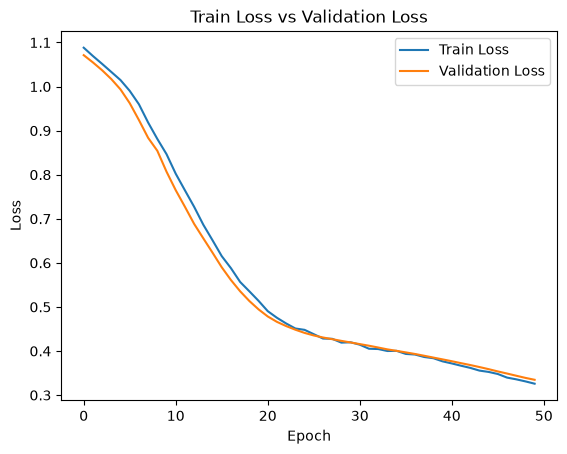

In [34]:
#GRAFICAR MODELO
import matplotlib.pyplot as plt

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train Loss vs Validation Loss")

plt.legend()

plt.show()

4. Try to improve results(obtain smaller losses): more/less hidden neurons, modify learning rate and batch size, more/less epochs,... 

In [35]:
model = nn.Sequential(
    nn.Linear(4, 20),
    nn.ReLU(),
    nn.Linear(20, 10),
    nn.ReLU(),
    nn.Linear(10, 3)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)#PROBAR A MEJORAR MODELO

5. Search for different initialization methods available with Pytorch. Which initialization method is used by default?

In [36]:
print(dir(nn.init)) #PESOS

['Callable', 'Literal', 'ParamSpec', 'Tensor', 'TypeVar', '_FanMode', '_NonlinearityType', '_P', '_R', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '_calculate_correct_fan', '_calculate_fan_in_and_fan_out', '_make_deprecate', '_no_grad_fill_', '_no_grad_normal_', '_no_grad_trunc_normal_', '_no_grad_uniform_', '_no_grad_zero_', 'calculate_gain', 'constant', 'constant_', 'dirac', 'dirac_', 'eye', 'eye_', 'kaiming_normal', 'kaiming_normal_', 'kaiming_uniform', 'kaiming_uniform_', 'math', 'normal', 'normal_', 'ones_', 'orthogonal', 'orthogonal_', 'sparse', 'sparse_', 'torch', 'trunc_normal_', 'uniform', 'uniform_', 'warnings', 'xavier_normal', 'xavier_normal_', 'xavier_uniform', 'xavier_uniform_', 'zeros_']


# Optimizers and avoiding overfitting

1. Optimizers
2. Dropout and Batch Normalization
3. Regularization
4. Early Stopping

## Optimizers

In [ ]:
optimizer = optim.SGD(model.parameters(), lr=0.1)
optimizer2 = optim.SGD(model.parameters(), lr=0.1,momentum=0.9) # Use Momentum
optimizer3 = optim.Adam(model.parameters(), lr=0.1) # Adam Optimizer
optimizer4 = optim.RMSprop(model.parameters(), lr=0.1) # RMSprop

## Dropout and Batch Normalization

In [ ]:
model = nn.Sequential(nn.Linear(2,4),
                      nn.Dropout(p=0.2), # 20% probability of Dropping out a neuron during training
                      nn.BatchNorm1d(num_features=4), # Apply batch normalization to the previous layer
                      nn.Linear(4, 2))

In [ ]:
nn.Dropout?

In [ ]:
nn.BatchNorm1d?

## Regularization

In [ ]:
# L2 regularization
optimizer = optim.SGD(model.parameters(), lr=0.1, weight_decay=0.1) # Lambda set to 0.1 for L2 regularization

In [ ]:
# L1 regularization
#loss = loss_fn(outputs, labels)
l1_lambda = 0.001 # Lambda for L1 regularizaiton
l1_norm = sum(torch.linalg.norm(p, 1) for p in model.parameters()) # Sum the absolute value of all parameters from the model

loss = loss + l1_lambda * l1_norm # Add the parameter contribution to the loss function

## Early stopping

In [ ]:
# EXAMPLE CODE: it will raise an error

patience = 3
min_delta = 10
counter = 0
min_validation_loss = float('inf')

for epoch in range(N_EPOCHS):
    train_loss = train_one_epoch(model, train_loader)
    validation_loss = validate_one_epoch(model, validation_loader)
    
    # Early stopping block
    if validation_loss < min_validation_loss:
        min_validation_loss = validation_loss
        counter = 0
    elif validation_loss > (min_validation_loss + min_delta):
        counter += 1
        if counter >= patience:
            break # If validation loss has not improved for a while, then stop training


# Exercises 1.3

1. Try different optimizers to improve the flower classification model, you may also add Dropout/Batch normalization or regularization.
2. Apply gradient clipping so that the norm of the gradient does not exceed 0.01. Is the norm computed per layer or for all parameters? [Documentation.](https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html) 
3.  Apply EarlyStopping, andsave the model with the lowest validation loss. Try different patience and min_delta values to observe how this affects how early training is stopped.
4. Change the training loop so that the learning rate starts at value 0.1 and decreases by a factor of 0.9 each epoch. [Example code.](https://machinelearningmastery.com/using-learning-rate-schedule-in-pytorch-training/)